In [1]:
# %%
"""
main.py
=======
Runner simulasi Federated Learning (Flower) + komparasi antar agregasi,
dengan opsi beberapa seed dan opsi pemilihan state (top10 / top20 / all).

Contoh (terminal):
    python main.py                                   # semua algoritma, SELECTION & SEEDS di bawah
    python main.py --select top20                    # pakai 20 state teratas
    python main.py --select all --seeds 0 1 2 3 4
    python main.py --algo fedpairwise --seeds 0 1    # satu algoritma
    python main.py --info                            # ringkasan data saja

Di Jupyter / VS Code Interactive:
    main(['--select', 'top10', '--seeds', '0', '1', '2'])

Output (di folder induk OUT_DIR, subfolder sesuai seleksi):
    <OUT_ROOT>/sel_top10/perbandingan_per_seed.csv
    <OUT_ROOT>/sel_top10/perbandingan_ringkasan.csv
    <OUT_ROOT>/sel_top10/perbandingan_berpasangan.csv
    <OUT_ROOT>/sel_top10/perbandingan_f1_per_client.csv
    <OUT_ROOT>/sel_top10/kurva_validasi.png
"""
import argparse
import os
import re
import shutil
import sys
import time
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
from flwr.simulation import run_simulation

import config
import fl_basic4 as fl          # <- ganti jika nama file strategy/client-mu berbeda
from dataset import DROP_COLS, TARGET
from model import build_model

# ============================================================
# 0. KONFIGURASI RUNNER
# ============================================================
SRC_CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
ALGOS = ['fedavg', 'fedprox', 'fedavgm', 'fedadam', 'fedpairwise']
BASELINE = 'fedavg'                      # pembanding untuk uji berpasangan
ORIG_OUT_DIR = Path(config.OUT_DIR)      # folder induk output = ORIG_OUT_DIR.parent
ORIG_SEED = int(config.SEED)

# Seed: tiap algoritma dijalankan sekali per seed.
SEEDS = [42, 22, 1]

# Pilih: "top10", "top20", atau "all"
SELECTION = "top10"

# Urutan state berdasarkan rata-rata F1 test run sebelumnya (rank 1 -> 20)
RANKED_STATES = [
    54, 13, 23, 5, 29, 16, 41, 19, 10, 39,   # top 10
    30, 22, 55, 33, 34, 37, 50, 48, 12, 1,   # rank 11-20
]
TOP_N = {"top10": 10, "top20": 20}

METRIC_COLS = ['acc', 'prec', 'rec', 'f1', 'auc',
               'f1_macro', 'f1_std_klien', 'total_MB', 'waktu_s']

# Diisi oleh setup_dataset(): folder yang benar-benar dipakai simulasi
CLIENT_DIR = SRC_CLIENT_DIR




2026-10-20 21:42:12,564	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [2]:

# %%
# ============================================================
# 1. SUBSET DATASET, MODUL & RINGKASAN DATA
# ============================================================
def _state_id(path: Path):
    """Ambil nomor state dari nama file/folder (angka pertama). None bila tidak ada."""
    m = re.search(r'\d+', path.stem)
    return int(m.group()) if m else None


def _copy_item(src: Path, dst: Path):
    if src.is_dir():
        shutil.copytree(src, dst)
    else:
        try:
            os.link(src, dst)           # hardlink: cepat & tanpa duplikasi
        except OSError:
            shutil.copy2(src, dst)


def build_subset_dir(selection):
    """Kembalikan folder client sesuai seleksi. 'all' -> folder asli."""
    if selection == "all":
        return SRC_CLIENT_DIR

    wanted = set(RANKED_STATES[:TOP_N[selection]])
    subset_dir = ORIG_OUT_DIR.parent / f'_clients_{selection}'
    if subset_dir.exists():
        shutil.rmtree(subset_dir)
    subset_dir.mkdir(parents=True, exist_ok=True)

    found = set()
    for item in sorted(SRC_CLIENT_DIR.iterdir()):
        sid = _state_id(item)
        if sid is None or sid in wanted:    # item tanpa nomor ikut disalin
            _copy_item(item, subset_dir / item.name)
            if sid is not None:
                found.add(sid)

    missing = wanted - found
    if missing:
        sys.exit(f"State tidak ditemukan di {SRC_CLIENT_DIR}: {sorted(missing)}")
    print(f"Subset {selection}: {len(found)} state -> {subset_dir}")
    return subset_dir


def setup_dataset(selection):
    """Arahkan config ke folder dataset (subset) dan buang cache data lama."""
    global CLIENT_DIR
    if not SRC_CLIENT_DIR.is_dir():
        sys.exit(f"Folder dataset tidak ditemukan: {SRC_CLIENT_DIR}")
    CLIENT_DIR = build_subset_dir(selection)
    config.CLIENT_DIR = CLIENT_DIR
    # Worker Ray membaca config.py sendiri, jadi folder dikirim lewat env var.
    os.environ['FL_CLIENT_DIR'] = str(CLIENT_DIR)
    try:                                   # pastikan tidak ada Ray lama dengan env lama
        import ray
        if ray.is_initialized():
            ray.shutdown()
    except ImportError:
        pass
    clear = getattr(fl.load_data, 'cache_clear', None)
    if clear:
        clear()
    n_item = sum(1 for _ in CLIENT_DIR.iterdir())
    print(f"Dataset : {CLIENT_DIR} ({n_item} item)")


def show_modules():
    print(f"Modul FL: {fl.__name__} ({Path(fl.__file__).name})")
    cls = getattr(fl, 'FedCosinePairwise', None)
    if cls is not None:
        print(f"Agregasi pairwise dari modul: {cls.__module__}")


def available_algos(algos):
    """Buang algoritma yang tidak dikenal oleh modul fl."""
    known = getattr(fl, 'ALGOS', algos)
    ok = [a for a in algos if a in known]
    skip = [a for a in algos if a not in ok]
    if skip:
        print(f"[lewati] tidak ada di {fl.__name__}.ALGOS: {skip}")
    return ok


def data_summary(selection):
    clients, scaler, feature_names = fl.load_data()
    n_clients = len(clients)
    n_fitur = fl.get_in_dim()
    assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"

    if selection != "all":
        expected = TOP_N[selection]
        assert n_clients == expected, (
            f"Seleksi {selection} harus {expected} client, terbaca {n_clients}")

    print("=" * 50)
    print(f"Seleksi               : {selection}")
    print(f"Jumlah client (state) : {n_clients}")
    print(f"Daftar state          : {fl.state_list()}")
    print(f"Target                : {TARGET}")
    print(f"Kolom dibuang         : {DROP_COLS}")
    print(f"Jumlah fitur          : {n_fitur}")
    print(f"Jumlah ronde          : {config.NUM_ROUNDS}")
    print(f"Client dilatih/ronde  : "
          f"{max(1, round(config.FRACTION_FIT * n_clients))} dari {n_clients}")
    print(f"Local epochs          : {config.LOCAL_EPOCHS}")
    print("=" * 50)
    for i, nama in enumerate(feature_names, 1):
        print(f"{i:>3}. {nama}")

    rows = {st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    } for st, c in clients.items()}

    ringkas = pd.DataFrame(rows).T
    ringkas.index.name = 'state'
    for s in ('train', 'val', 'test'):
        ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)

    total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
    for s in ('train', 'val', 'test'):
        total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
    ringkas.loc['TOTAL'] = total

    print("\nRingkasan per client:")
    print(ringkas.to_string())

    total_train = sum(len(c['y_train_t']) for c in clients.values())
    print("\nscaler.n_samples_seen_ vs total train:",
          scaler.n_samples_seen_, total_train, "(harus sama)")
    return n_clients


# %%
# ============================================================
# 2. JALANKAN SATU (ALGORITMA, SEED)
# ============================================================
def run_algo(algo, seed, n_clients, out_root):
    """Simulasi FL untuk satu algoritma & seed; output ke out_root/out_<algo>_s<seed>."""
    config.SEED = seed
    os.environ['FL_SEED'] = str(seed)      # dibaca server (fl_basic3.get_seed)
    config.OUT_DIR = out_root / f'out_{algo}_s{seed}'
    config.ensure_out_dir()
    # hapus sisa run sebelumnya supaya tidak terbaca sebagai hasil run ini
    for nama in ('final_params.npz', 'ronde_log.csv'):
        (config.OUT_DIR / nama).unlink(missing_ok=True)
    print(f"\n########## {algo} | seed {seed} ##########")
    run_simulation(
        server_app=fl.make_server_app(algo),
        client_app=fl.make_client_app(),
        num_supernodes=n_clients,
        backend_config={"client_resources": {"num_cpus": 1, "num_gpus": 0.0}},
    )


def load_global_model():
    """Bangun model global dari final_params.npz di config.OUT_DIR saat ini."""
    path = config.OUT_DIR / 'final_params.npz'
    if not path.exists():
        raise FileNotFoundError(
            f"{path} tidak ada: simulasi gagal sebelum ada ronde yang selesai. "
            f"Cek {config.OUT_DIR / 'client_error.log'}")
    d = np.load(path)
    w = [d[f'arr_{i}'] for i in range(len(d.files))]
    m = build_model(fl.get_in_dim(), seed=config.SEED).to(config.DEVICE)
    fl.set_weights(m, w)
    return m


def run_single(algo, seeds, n_clients, out_root):
    try:
        for seed in seeds:
            run_algo(algo, seed, n_clients, out_root)

            rep, ronde = fl.bandwidth_report()
            print(ronde.round(4).to_string(index=False))

            model = load_global_model()
            df_test = fl.evaluate_on_clients(model, split='test')
            print(df_test.round(4).to_string())
            print(fl.summarize(df_test).round(4).to_string())
            print("Pooled:", fl.evaluate_pooled(model, split='test'))
    finally:
        config.SEED = ORIG_SEED


In [3]:

# %%
# ============================================================
# 3. KOMPARASI ANTAR AGREGASI (multi-seed)
# ============================================================
def collect_result(secs):
    """Kumpulkan hasil run yang baru selesai (config.OUT_DIR sudah menunjuk ke run itu)."""
    model = load_global_model()
    pooled = fl.evaluate_pooled(model, split='test')
    df_test = fl.evaluate_on_clients(model, split='test')
    ronde = pd.read_csv(config.OUT_DIR / 'ronde_log.csv')
    bw, _ = fl.bandwidth_report(verbose=False)

    f1 = ronde['f1'].astype(float)
    if f1.notna().any():
        best = f1.idxmax()
        val_best, best_round = float(f1[best]), int(ronde.loc[best, 'round'])
    else:
        val_best, best_round = float('nan'), -1

    row = {
        **{k: float(v) for k, v in pooled.items()},      # metrik test gabungan
        'f1_macro':       float(df_test['f1'].mean()),   # rata-rata antar state
        'f1_std_klien':   float(df_test['f1'].std()),    # ketimpangan antar state
        'val_f1_akhir':   float(f1.iloc[-1]),
        'val_f1_terbaik': val_best,
        'ronde_terbaik':  best_round,
        'total_MB':       float(bw['total_MB']),
        'waktu_s':        round(secs, 1),
    }
    return row, df_test['f1'], ronde


def _fmt(mean, std, n, nd=4):
    if n < 2 or pd.isna(std):
        return f"{mean:.{nd}f}"
    return f"{mean:.{nd}f} ± {std:.{nd}f}"


def summarize_seeds(per_seed):
    """Rata-rata & simpangan antar seed untuk tiap algoritma."""
    cols = [c for c in METRIC_COLS if c in per_seed.columns]
    g = per_seed.groupby(level='algoritma')[cols]
    mean, std = g.mean(), g.std()
    n = g.size().rename('n_seed')

    num = pd.concat({'mean': mean, 'std': std}, axis=1)
    num.columns = [f'{c}_{stat}' for stat, c in num.columns]
    num.insert(0, 'n_seed', n)
    num = num.sort_values('f1_mean', ascending=False)

    tampil = pd.DataFrame(index=num.index)
    tampil['n_seed'] = num['n_seed']
    for c in cols:
        nd = 2 if c in ('total_MB', 'waktu_s') else 4
        tampil[c] = [_fmt(num.loc[a, f'{c}_mean'], num.loc[a, f'{c}_std'],
                          int(num.loc[a, 'n_seed']), nd) for a in num.index]
    return num, tampil


def _pvalue(d):
    """Uji-t berpasangan (selisih d terhadap 0). NaN bila tidak bisa dihitung."""
    if len(d) < 3 or float(d.std()) == 0.0:
        return float('nan')
    try:
        from scipy import stats
    except ImportError:
        return float('nan')
    return float(stats.ttest_1samp(d, 0.0).pvalue)


def paired_vs_baseline(per_seed, baseline, metrics=('f1', 'auc')):
    """Selisih tiap algoritma terhadap baseline pada seed yang sama."""
    algos = list(per_seed.index.get_level_values('algoritma').unique())
    if baseline not in algos:
        return None
    base = per_seed.xs(baseline, level='algoritma')
    out = []
    for algo in algos:
        if algo == baseline:
            continue
        cur = per_seed.xs(algo, level='algoritma')
        seeds = base.index.intersection(cur.index)
        if len(seeds) == 0:
            continue
        row = {'algoritma': algo, 'n_seed': len(seeds)}
        for m in metrics:
            d = (cur.loc[seeds, m] - base.loc[seeds, m]).astype(float)
            row[f'd{m}_mean'] = float(d.mean())
            row[f'd{m}_std'] = float(d.std()) if len(d) > 1 else float('nan')
            row[f'{m}_menang'] = f"{int((d > 0).sum())}/{len(d)}"
            row[f'{m}_p'] = _pvalue(d)
        out.append(row)
    return pd.DataFrame(out).set_index('algoritma') if out else None


def plot_curves(kurva, out_path):
    """F1 & AUC validasi per ronde: rata-rata antar seed, pita = ± std."""
    try:
        import matplotlib
        if 'ipykernel' not in sys.modules:
            matplotlib.use('Agg')
        import matplotlib.pyplot as plt
    except ImportError:
        print("[lewati grafik] matplotlib belum terpasang (pip install matplotlib)")
        return

    per_algo = {}
    for (algo, _), ronde in kurva.items():
        per_algo.setdefault(algo, []).append(ronde)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, col, judul in zip(axes, ('f1', 'auc'), ('F1 validasi', 'AUC validasi')):
        for algo, rs in per_algo.items():
            m = pd.concat([r.set_index('round')[col] for r in rs], axis=1)
            mu, sd = m.mean(axis=1), m.std(axis=1)
            ax.plot(mu.index, mu.values, marker='o', ms=3,
                    label=f'{algo} (n={len(rs)})')
            if len(rs) > 1:
                ax.fill_between(mu.index, (mu - sd).values, (mu + sd).values, alpha=0.15)
        ax.set_xlabel('Ronde')
        ax.set_ylabel(judul)
        ax.set_title(f'{judul} per ronde (rata-rata ± std antar seed)')
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    print(f"Grafik disimpan: {out_path}")
    if 'ipykernel' in sys.modules:
        plt.show()
    else:
        plt.close(fig)


def run_compare(algos, seeds, n_clients, out_root):
    rows, f1_klien, kurva = {}, {}, {}
    total_run = len(algos) * len(seeds)
    print(f"\nKomparasi: {len(algos)} algoritma x {len(seeds)} seed = {total_run} run")
    print(f"Seed: {seeds}")

    try:
        for seed in seeds:                 # seed di luar: hasil parsial tetap seimbang
            for algo in algos:
                t0 = time.perf_counter()
                try:
                    run_algo(algo, seed, n_clients, out_root)
                    row, f1c, ronde = collect_result(time.perf_counter() - t0)
                except Exception:
                    print(f"[GAGAL] {algo} seed {seed}:\n{traceback.format_exc()}")
                    continue
                key = (algo, seed)
                rows[key], f1_klien[key], kurva[key] = row, f1c, ronde
                print(f"[selesai] {algo} s{seed}: F1 test {row['f1']:.4f} | "
                      f"AUC {row['auc']:.4f} | {row['total_MB']:.2f} MB | "
                      f"{row['waktu_s']} s")
    finally:
        config.SEED = ORIG_SEED

    if not rows:
        sys.exit("Tidak ada run yang berhasil.")

    idx = pd.MultiIndex.from_tuples(list(rows.keys()), names=['algoritma', 'seed'])
    per_seed = pd.DataFrame(list(rows.values()), index=idx)

    num, tampil = summarize_seeds(per_seed)
    berpasangan = paired_vs_baseline(per_seed, BASELINE)

    per_klien = pd.DataFrame({
        algo: pd.concat([f1_klien[k] for k in f1_klien if k[0] == algo], axis=1).mean(axis=1)
        for algo in num.index
    })
    per_klien.loc['MAKRO'] = per_klien.mean()

    print("\n" + "=" * 70)
    print("PERBANDINGAN AGREGASI  (rata-rata ± simpangan antar seed; urut F1)")
    print("=" * 70)
    print(tampil.to_string())

    print("\nHasil per seed (F1 | AUC test gabungan):")
    print(per_seed[['f1', 'auc']].round(4).unstack('seed').to_string())

    if berpasangan is not None:
        print(f"\nSelisih terhadap {BASELINE} pada seed yang sama "
              f"(positif = lebih baik dari {BASELINE}):")
        print(berpasangan.round(4).to_string())
        if int(berpasangan['n_seed'].min()) < 5:
            print("Catatan: dengan <5 seed uji-t lemah; jangan terlalu bergantung "
                  "pada p-value. Lihat kolom *_menang dan konsistensi arah selisih.")
    elif len(seeds) > 1:
        print(f"\n[uji berpasangan dilewati] baseline '{BASELINE}' tidak ikut/ gagal.")

    print("\nF1 test per state (rata-rata antar seed):")
    print(per_klien.round(4).to_string())

    print(f"\nTerbaik F1 (rata-rata)    : {num['f1_mean'].idxmax()}")
    print(f"Terbaik AUC (rata-rata)   : {num['auc_mean'].idxmax()}")
    if len(seeds) > 1:
        print(f"Paling stabil antar seed  : {num['f1_std'].idxmin()} (std F1 terkecil)")
    print(f"Paling merata antar state : {num['f1_std_klien_mean'].idxmin()}")
    mb = num['total_MB_mean']
    if (mb.max() - mb.min()) > 0.01 * mb.max():      # abaikan bila praktis sama
        print(f"Bandwidth terkecil        : {mb.idxmin()}")
    else:
        print("Bandwidth                 : sama untuk semua algoritma (ukuran parameter sama)")

    out_root.mkdir(parents=True, exist_ok=True)
    per_seed.to_csv(out_root / 'perbandingan_per_seed.csv')
    num.to_csv(out_root / 'perbandingan_ringkasan.csv')
    per_klien.to_csv(out_root / 'perbandingan_f1_per_client.csv')
    if berpasangan is not None:
        berpasangan.to_csv(out_root / 'perbandingan_berpasangan.csv')
    print(f"\nCSV disimpan di: {out_root}")
    plot_curves(kurva, out_root / 'kurva_validasi.png')
    return per_seed, num



Modul FL: fl_basic4 (fl_basic4.py)
Agregasi pairwise dari modul: aggregation4
Subset top10: 10 state -> C:\Users\s2\Documents\FIXRKI\selectedclient\top10\_clients_top10
Dataset : C:\Users\s2\Documents\FIXRKI\selectedclient\top10\_clients_top10 (11 item)
Seleksi               : top10
Jumlah client (state) : 10
Daftar state          : [5, 10, 13, 16, 19, 23, 29, 39, 41, 54]
Target                : _michd
Kolom dibuang         : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']
Jumlah fitur          : 69
Jumlah ronde          : 10
Client dilatih/ronde  : 10 dari 10
Local epochs          : 5
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwalk
 28. diffdres
 29. diffalon
 30. _rfbing6
 31. drnka

INFO :      Starting Flower ServerApp, config: num_rounds=10, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Evaluating initial global parameters
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)


[server] algoritma agregasi: fedavg | seed: 42


INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      configure_evaluate: strategy sampled 10 clients (out of 10)
INFO :      aggregate_evaluate: received 10 results and 0 failures
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)


[ronde 01] val F1 0.5032 | AUC 0.7477 | bandwidth ronde 0.795 MB


...

[ronde 10] bobot pairwise: 29=0.101, 19=0.101, 39=0.084, 41=0.107, 5=0.104, 54=0.105, 13=0.101, 16=0.103, 23=0.096, 10=0.099


INFO :      aggregate_evaluate: received 10 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 10 round(s) in 30.51s
INFO :      	History (loss, distributed):
INFO :      		round 1: 0.5983831439218262
INFO :      		round 2: 0.6005445049016009
INFO :      		round 3: 0.6068592575820098
INFO :      		round 4: 0.6158100746999563
INFO :      		round 5: 0.6263736298835698
INFO :      		round 6: 0.6348753104899529
INFO :      		round 7: 0.6469143302316329
INFO :      		round 8: 0.6657037037716917
INFO :      		round 9: 0.6841745761942315
INFO :      		round 10: 0.6996186566950106
INFO :      	History (metrics, distributed, fit):
INFO :      	{'agg_weight_10': [(1, 0.1303651464727964),
INFO :      	                   (2, 0.11340555661654907),
INFO :      	                   (3, 0.10878730800158302),
INFO :      	                   (4, 0.10491391215510897),
INFO :      	                   (5, 0.10373009395583083),
INFO :      	                   (6, 0.10555213041

[ronde 10] val F1 0.4774 | AUC 0.7210 | bandwidth ronde 0.795 MB


INFO :      	                   (9, 0.09521339052659736),
INFO :      	                   (10, 0.09622444470965665)],
INFO :      	 'agg_weight_29': [(1, 0.1026805726292749),
INFO :      	                   (2, 0.1101879243841654),
INFO :      	                   (3, 0.10659315453941832),
INFO :      	                   (4, 0.10050894324011522),
INFO :      	                   (5, 0.10478717904048127),
INFO :      	                   (6, 0.10686011821618321),
INFO :      	                   (7, 0.1013850652854723),
INFO :      	                   (8, 0.10363281936431054),
INFO :      	                   (9, 0.1007599299482928),
INFO :      	                   (10, 0.10077486897513321)],
INFO :      	 'agg_weight_39': [(1, 0.04117351685108991),
INFO :      	                   (2, 0.05505266700107892),
INFO :      	                   (3, 0.06118557389398826),
INFO :      	                   (4, 0.06239249881344047),
INFO :      	                   (5, 0.06602823535306762),
INFO :      	 

[selesai] fedpairwise s1: F1 test 0.5069 | AUC 0.7366 | 7.95 MB | 36.4 s

PERBANDINGAN AGREGASI  (rata-rata ± simpangan antar seed; urut F1)
             n_seed              acc             prec              rec               f1              auc         f1_macro     f1_std_klien     total_MB       waktu_s
algoritma                                                                                                                                                            
fedprox           3  0.7038 ± 0.0052  0.4258 ± 0.0058  0.6123 ± 0.0085  0.5023 ± 0.0035  0.7341 ± 0.0036  0.5027 ± 0.0063  0.0282 ± 0.0040  7.95 ± 0.00  45.17 ± 0.06
fedavg            3  0.7062 ± 0.0046  0.4278 ± 0.0052  0.6027 ± 0.0115  0.5004 ± 0.0040  0.7321 ± 0.0032  0.5000 ± 0.0061  0.0241 ± 0.0052  7.95 ± 0.00  35.80 ± 0.78
fedpairwise       3  0.7060 ± 0.0043  0.4269 ± 0.0063  0.5974 ± 0.0129  0.4979 ± 0.0082  0.7329 ± 0.0040  0.4952 ± 0.0065  0.0346 ± 0.0125  7.95 ± 0.00  35.80 ± 0.79
fedadam           3  0.6784 ±

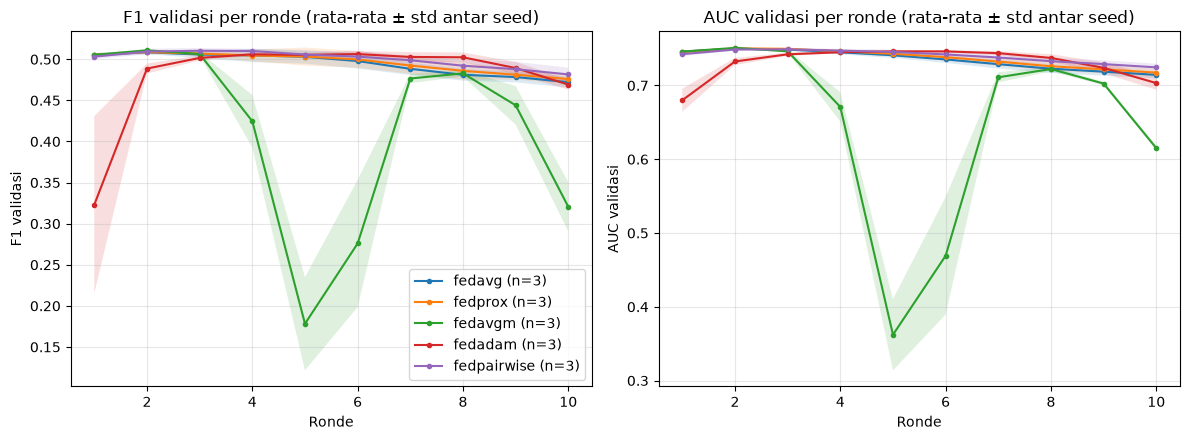

In [4]:

# %%
# ============================================================
# 4. ENTRY POINT  (guard wajib untuk Ray/multiprocessing di Windows)
# ============================================================
def main(argv=None):
    ap = argparse.ArgumentParser(description="Simulasi Federated Learning")
    ap.add_argument('--algo', default=None, choices=ALGOS,
                    help="jalankan satu algoritma saja (tanpa komparasi)")
    ap.add_argument('--compare', action='store_true',
                    help="komparasi (default bila --algo tidak diberikan)")
    ap.add_argument('--algos', nargs='+', choices=ALGOS, default=ALGOS,
                    help="daftar algoritma untuk komparasi")
    ap.add_argument('--seeds', nargs='+', type=int, default=None,
                    help="timpa SEEDS di atas, mis. --seeds 0 1 2 3 4 (opsional)")
    ap.add_argument('--select', default=None, choices=['top10', 'top20', 'all'],
                    help="timpa SELECTION di atas (opsional)")
    ap.add_argument('--info', action='store_true',
                    help="hanya tampilkan ringkasan data")
    # parse_known_args: abaikan argumen asing (mis. --f=kernel.json dari Jupyter)
    args, _ = ap.parse_known_args(argv)

    seeds = list(dict.fromkeys(args.seeds)) if args.seeds else list(dict.fromkeys(SEEDS))
    selection = args.select or SELECTION

    show_modules()
    setup_dataset(selection)
    n_clients = data_summary(selection)
    if args.info:
        return

    # tiap seleksi punya folder hasil sendiri, tidak menimpa run lain
    out_root = ORIG_OUT_DIR.parent / f'sel_{selection}'
    out_root.mkdir(parents=True, exist_ok=True)

    if args.algo and not args.compare:
        run_single(args.algo, seeds, n_clients, out_root)
    else:
        run_compare(available_algos(args.algos), seeds, n_clients, out_root)


if __name__ == '__main__':
    main()